In [1]:
import geopandas as gpd 

import contextily as cx
import xyzservices.providers as xyz


print(gpd.__version__)

1.2.0


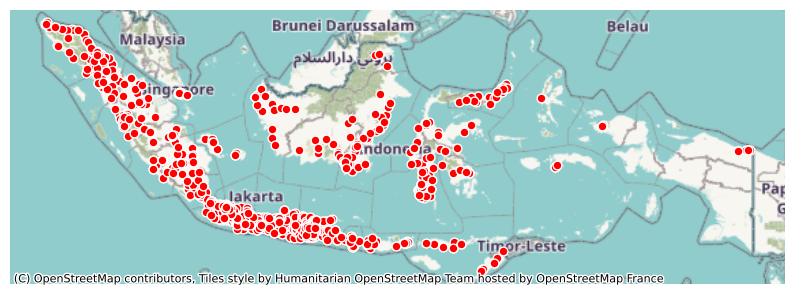

In [2]:
gardu = gpd.read_file("gardu_induk.gpkg")
gardu_3857 = gardu.to_crs(epsg=3857)


ax = gardu_3857.plot(figsize=(10, 10), color="red", edgecolor="white", markersize=40)
cx.add_basemap(ax)
ax.set_axis_off()

In [3]:
gardu.head(5)

,teggi,thnopr,alamat,fcode,remark,objectid_1,objectid,namaobj,kapgi,statmlk,statopr,regpln,srs_id,geometry
0,150 kV,2000,"Komplek PLTU Asam-Asam, Asam-Asam, Jorong, Tan...",HB01050020,PLN UIKL Kalimantan,1,17,GI 150 kV Asam-asam,40.0,PLN,Operasi,Kalimantan,4326,POINT (115.10494 -3.92532)
1,70 kV,1973,"Aranio, Aranio, Banjar, Kalimantan Selatan",HB01050020,PLN UIKL Kalimantan,2,18,GI 70 kV PLTA IR. PM NOOR,6.0,PLN,Operasi,Kalimantan,4326,POINT (115.0079 -3.5156)
2,70 kV,1973,"Jalan Mistar Cokrokusumo Banjarbaru, Sei Besar...",HB01050020,PLN UIKL Kalimantan,3,19,GI 70 kV Cempaka,20.0,PLN,Operasi,Kalimantan,4326,POINT (114.85019 -3.46557)
3,70 kV,1983,"Jalan Ir. P. Moch. Noor, Banjarmasin, Trisakti...",HB01050020,PLN UIKL Kalimantan,4,20,GI 70 kV Trisakti,35.0,PLN,Operasi,Kalimantan,4326,POINT (114.5703 -3.30918)
4,150 kV,2006,"Kalawa, Kahayan Hilir, Pulang Pisau, 73564, Ka...",HB01050020,PLN UIKL Kalimantan,5,21,GI 150 kV Pulang Pisau,10.0,PLN,Operasi,Kalimantan,4326,POINT (114.25468 -2.73165)


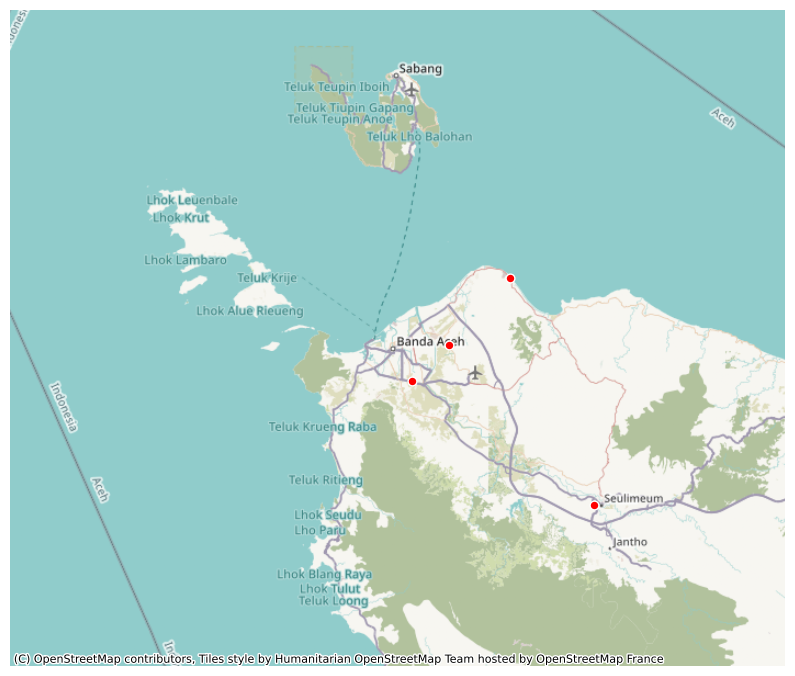

In [4]:
# zoom extent (minx, miny, maxx, maxy) in EPSG:4326
minx, miny, maxx, maxy = 94.839505, 5.157846, 95.80944, 5.975077

(xmin, ymin), (xmax, ymax) = (
    gpd.GeoSeries.from_xy([minx, maxx], [miny, maxy], crs=4326).to_crs(3857).apply(lambda p: (p.x, p.y))
)

ax = gardu_3857.plot(figsize=(10, 10), color="red", edgecolor="white", markersize=40)
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
cx.add_basemap(ax)
ax.set_axis_off()

Total buffer area: 466784.88 km2


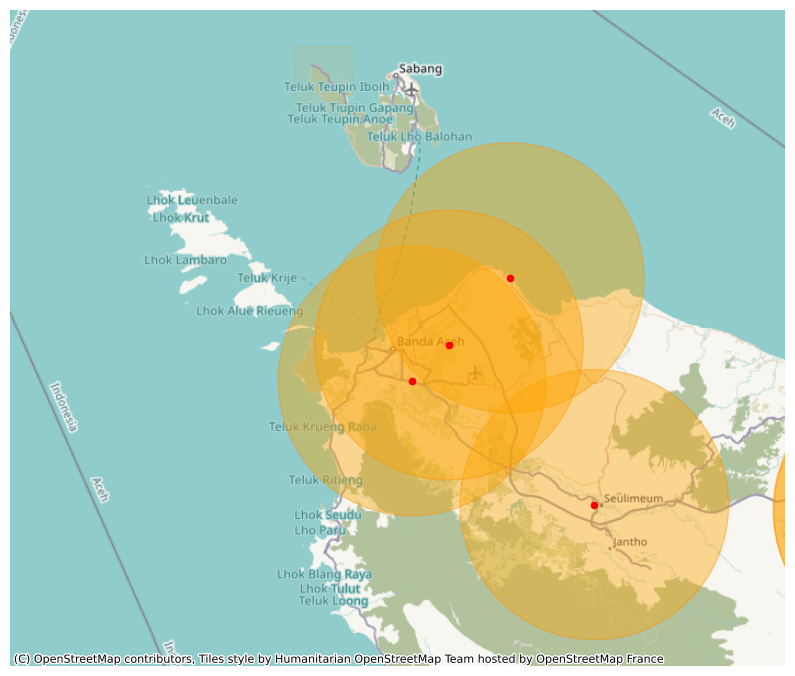

In [5]:
# buffer analysis, 20 km. Use a metric CRS so distance is in meters
gardu_utm = gardu.to_crs(gardu.estimate_utm_crs())
buffer_20km = gardu_utm.copy()
buffer_20km["geometry"] = gardu_utm.buffer(20000)

# back to 3857 to plot over basemap
buffer_3857 = buffer_20km.to_crs(epsg=3857)

ax = buffer_3857.plot(figsize=(10, 10), color="orange", alpha=0.4, edgecolor="darkorange")
gardu_3857.plot(ax=ax, color="red", markersize=20)
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
cx.add_basemap(ax)
ax.set_axis_off()

# dissolved buffer area (overlaps merged), km2
print(f"Total buffer area: {buffer_20km.union_all().area / 1e6:.2f} km2")

In [6]:
# export to folium map, index.html to be shown on the web.
# clip to the zoom extent first so index.html stays small
gardu_clip = gardu.cx[minx:maxx, miny:maxy].copy()

# 20 km buffer in a metric CRS, back to 4326 for folium
gardu_clip_utm = gardu_clip.to_crs(gardu_clip.estimate_utm_crs())
buffer_clip = gardu_clip_utm.copy()
buffer_clip["geometry"] = gardu_clip_utm.buffer(20000)
buffer_clip = buffer_clip.to_crs(4326)

cols = ["namaobj", "teggi", "kapgi", "statopr", "thnopr", "alamat"]

m = buffer_clip[cols + ["geometry"]].explore(
    color="darkorange", name="20 km buffer", tiles="OpenStreetMap",
    style_kwds={"fillOpacity": 0.2, "weight": 1}, tooltip=False, control_scale=True,
)
m = gardu_clip[cols + ["geometry"]].explore(
    m=m, color="red", name="Substation (Gardu Induk)", tooltip=["namaobj", "teggi", "kapgi", "statopr"],
    popup=cols, marker_kwds={"radius": 6},
)
m.fit_bounds([[miny, minx], [maxy, maxx]])

import folium
folium.LayerControl().add_to(m)

m.save("index.html")
m